In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def linear_f(x,w,b):
    #Multivariate linear function
    #return vector of y predict
    #[y1,y2,y4] = #[x1w1 +b ,x2w2+b,x3w3+b..]

    return x @ w + b

def mse_loss(x,y,w,b):
    #loss per sample
    #return loss vector
    y_pred = linear_f(x,w,b)
    return 0.5 * (y - y_pred) ** 2

def grad_w_mse(x,y,w,b):

    return (linear_f(x,w,b)-y) * x

def grad_b_mse(x,y,w,b):

    return (linear_f(x,w,b)-y) * 1


def Gradient_decent(x,y,learning_rate,batch_size,epochs,seed = None,grad_reduce="mean"):
    """
    Gradient descent algorithm to optimize the weight and bias
    :param x: input data
    :param y: true labels
    :param learning_rate: learning rate for gradient descent
    :param batch_size: size of each batch for mini-batch gradient descent
    :param epochs: number of iterations for gradient descent
    :return: optimized weight and bias
    """

    #N  is number of data, D is dimention of x
    N,D = x.shape
    
    rng = np.random.default_rng(seed)
    w = rng.standard_normal(D)
    b = rng.standard_normal()

    history = {'w': [w], 'b': [b], 'loss': [np.mean(mse_loss(x,y,w,b))]}

    points = 0

    for epoch in range(epochs):
        #suffle data with idx
        idx = rng.permutation(N)
        #idx is array of suffle number between 0 ~ N 
        
        for start in range(0,N,batch_size):
            #from 0 ~ N step of batch_size
            
            batch = idx[start:start+batch_size]

            #dw => 0 vector sizeOF D
            #db = 0
            dw,db = np.zeros(D),0.0

            for j in batch :
                dw = dw + grad_w_mse(x[j],y[j],w,b)
                db = db + grad_b_mse(x[j],y[j],w,b)
            if grad_reduce == "mean":
                dw /= len(batch)
                db /= len(batch)

            w = w - learning_rate*dw
            b = b - learning_rate*db

            loss = np.mean(mse_loss(x,y,w,b))
            history['w'].append(w.copy())
            history['b'].append(b)
            history['loss'].append(loss)

            print(f"Epoch {epoch+1}/{epochs}, Loss: {loss:.4f}, "
            f"w: {np.round(w, 3)}, b: {b:.4f}")

    plt.plot(history['loss'])
    plt.xlabel("Epochs"); plt.ylabel("Loss"); plt.show()
    return history


def Normal_equation(x, y):
    """
    Normal equation: theta = (X^T X)^(-1) X^T y
    :param x: input data (N, D)
    :param y: true labels (N,)
    :return: w (D,), b (scalar)
    """
    N, D = x.shape

    # bias 항을 위해 1로 이루어진 열을 추가 -> (N, D+1)
    X_b = np.hstack([x, np.ones((N, 1))])


    # theta = [w1, ..., wD, b]
    theta = np.linalg.solve(X_b.T @ X_b, X_b.T @ y)

    #theta는 bias를 포함한 w벡터


    w = theta[:-1]
    
    #theta의 맨 마지막은 bias
    b = theta[-1]
    return w, b

            

Epoch 1/30, Loss: 0.7742, w: [0.306], b: -0.9943
Epoch 1/30, Loss: 0.6973, w: [0.347], b: -0.9381
Epoch 1/30, Loss: 0.6535, w: [0.357], b: -0.8961
Epoch 1/30, Loss: 0.5974, w: [0.39], b: -0.8508
Epoch 1/30, Loss: 0.5338, w: [0.436], b: -0.7991
Epoch 1/30, Loss: 0.4875, w: [0.461], b: -0.7533
Epoch 1/30, Loss: 0.4405, w: [0.499], b: -0.7094
Epoch 1/30, Loss: 0.4206, w: [0.508], b: -0.6855
Epoch 1/30, Loss: 0.3811, w: [0.545], b: -0.6454
Epoch 1/30, Loss: 0.3587, w: [0.574], b: -0.6248
Epoch 1/30, Loss: 0.3474, w: [0.576], b: -0.6072
Epoch 1/30, Loss: 0.3187, w: [0.599], b: -0.5697
Epoch 1/30, Loss: 0.2999, w: [0.616], b: -0.5439
Epoch 1/30, Loss: 0.2743, w: [0.65], b: -0.5108
Epoch 1/30, Loss: 0.2563, w: [0.666], b: -0.4816
Epoch 1/30, Loss: 0.2488, w: [0.662], b: -0.4639
Epoch 1/30, Loss: 0.2386, w: [0.66], b: -0.4404
Epoch 1/30, Loss: 0.2303, w: [0.662], b: -0.4221
Epoch 1/30, Loss: 0.2180, w: [0.662], b: -0.3919
Epoch 1/30, Loss: 0.2080, w: [0.665], b: -0.3671
Epoch 1/30, Loss: 0.199

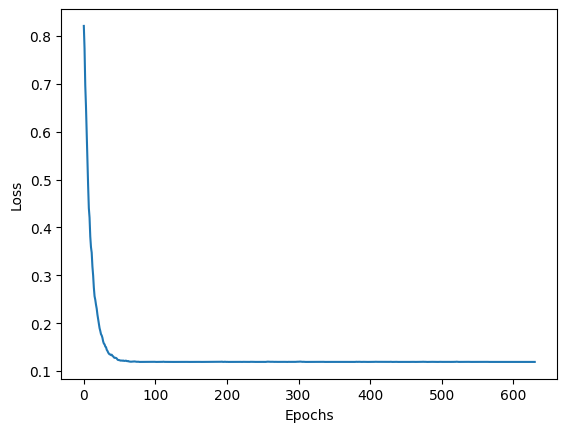

[ 8.72978899e-01 -2.12939464e-16]


In [ ]:
import seaborn as sns


df = sns.load_dataset("penguins").dropna()

#팔길이 입력으로 받아서 몸무게를 예측하는 문제

x_raw = df["flipper_length_mm"].values
y_raw = df["body_mass_g"].values


#Z - 표준화 (0,1)
#학습 시킬때는 표준화 해서 하는 게 좋다 이유는 뭘까?
X = ((x_raw-x_raw.mean()) / x_raw.std()).reshape(-1,1)
Y = ((y_raw-y_raw.mean()) / y_raw.std())

history = Gradient_decent(X, Y, learning_rate=0.05, batch_size=16, epochs=30, seed=42)

A = np.c_[X, np.ones(len(X))]
print(np.linalg.lstsq(A, Y, rcond=None)[0])   # [w, b]


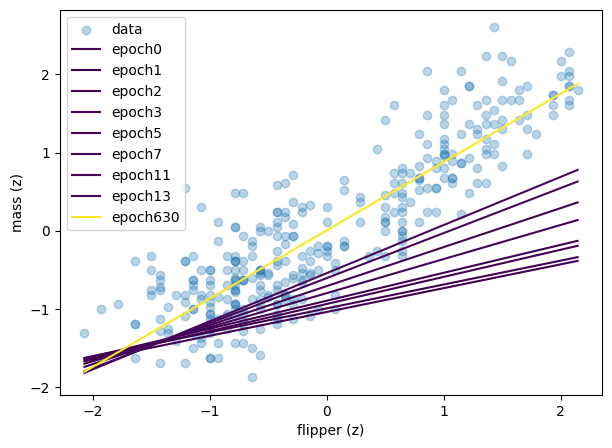

In [ ]:
xs = np.linspace(X.min(), X.max(),100)
#xs == > x의 최대 최소값 직선의 양끝점
E= len(history['w'])

plt.figure(figsize=(7,5))
plt.scatter(X[:,0], Y , alpha=0.3, label = "data")

cmap = plt.cm.viridis
for k in range(E):
    if k in (0,1,2,3,5,7,11,13,E-1):
        w = history['w'][k]
        b = history['b'][k]

        #plot에 100개의 점을 준다

        plt.plot(xs,w[0]*xs + b, color =cmap(k/(E-1)),label = f"epoch{k}")

plt.legend(); plt.xlabel("flipper (z)"); plt.ylabel("mass (z)")
plt.show()


Epoch 1/30, Loss: 1.2504, w: [ 0.377 -0.947], b: 0.6866
Epoch 1/30, Loss: 1.1043, w: [ 0.422 -0.889], b: 0.6474
Epoch 1/30, Loss: 0.9423, w: [ 0.465 -0.81 ], b: 0.6012
Epoch 1/30, Loss: 0.8248, w: [ 0.519 -0.759], b: 0.5738
Epoch 1/30, Loss: 0.7366, w: [ 0.553 -0.709], b: 0.5527
Epoch 1/30, Loss: 0.6881, w: [ 0.583 -0.69 ], b: 0.5393
Epoch 1/30, Loss: 0.6325, w: [ 0.61  -0.662], b: 0.5177
Epoch 1/30, Loss: 0.5520, w: [ 0.646 -0.611], b: 0.4868
Epoch 1/30, Loss: 0.4753, w: [ 0.699 -0.557], b: 0.4732
Epoch 1/30, Loss: 0.4057, w: [ 0.74  -0.507], b: 0.4366
Epoch 1/30, Loss: 0.3657, w: [ 0.76  -0.475], b: 0.4082
Epoch 1/30, Loss: 0.3357, w: [ 0.778 -0.447], b: 0.3902
Epoch 1/30, Loss: 0.2957, w: [ 0.805 -0.407], b: 0.3623
Epoch 1/30, Loss: 0.2771, w: [ 0.831 -0.388], b: 0.3575
Epoch 1/30, Loss: 0.2603, w: [ 0.847 -0.369], b: 0.3453
Epoch 1/30, Loss: 0.2436, w: [ 0.856 -0.353], b: 0.3204
Epoch 1/30, Loss: 0.2329, w: [ 0.859 -0.338], b: 0.3072
Epoch 1/30, Loss: 0.2140, w: [ 0.873 -0.313], b:

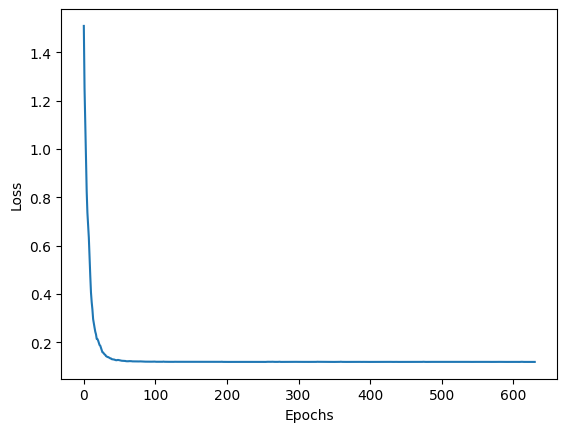

[ 8.50984846e-01  3.36766189e-02 -2.49443373e-16]


In [24]:
import seaborn as sns

df = sns.load_dataset("penguins").dropna()

X_raw = df[["flipper_length_mm", "bill_length_mm"]].values
y_raw = df["body_mass_g"].values

#mean(axis) -- > feature mean, feature std
#mean(axis = 0 --> 열의 평균을 계산 --> 특징의 평균을 계산)
#
X = (X_raw - X_raw.mean(0)) / X_raw.std(0)    # (N, 2) 특징별 표준화
Y = (y_raw - y_raw.mean()) / y_raw.std()

history = Gradient_decent(X, Y, learning_rate=0.05, batch_size=16, epochs=30, seed=42)

A = np.c_[X, np.ones(len(X))]
print(np.linalg.lstsq(A, Y, rcond=None)[0])   # [w1, w2, b] 와 비교

In [25]:
W = np.array(history['w'])
B = np.array(history['b'])
L = np.array(history['loss'])

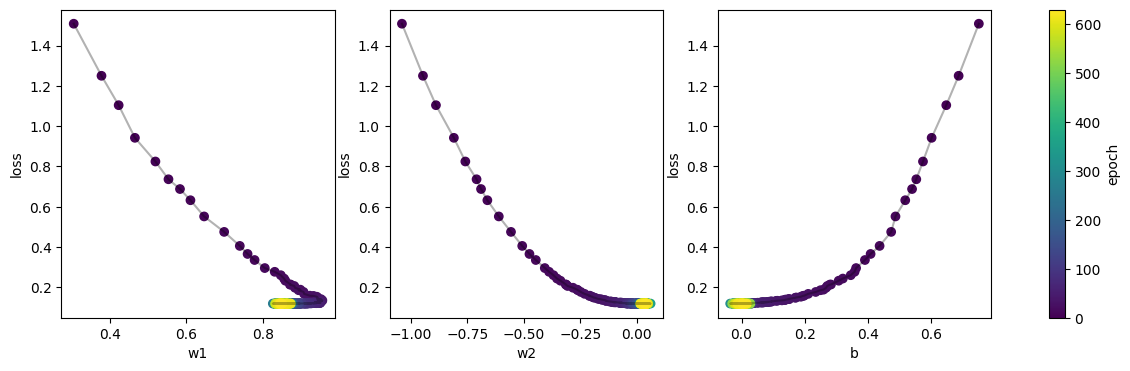

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, p, name in zip(axes, [W[:, 0], W[:, 1], B], ["w1", "w2", "b"]):
    ax.plot(p, L, 'k-', alpha=0.3)
    sc = ax.scatter(p, L, c=np.arange(len(L)), cmap='viridis')
    ax.set_xlabel(name); ax.set_ylabel("loss")
fig.colorbar(sc, ax=axes, label="epoch")
plt.show()

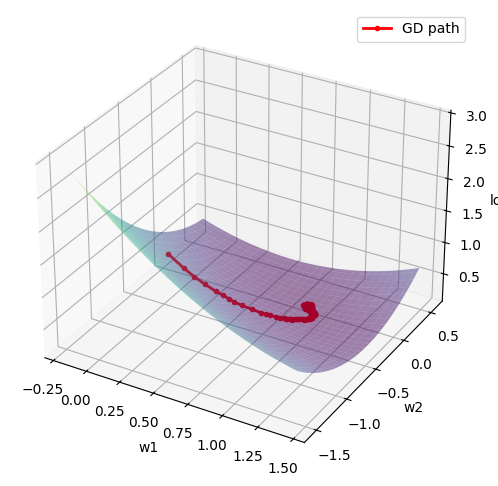

In [28]:
w1s = np.linspace(W[:, 0].min() - 0.5, W[:, 0].max() + 0.5, 60)
w2s = np.linspace(W[:, 1].min() - 0.5, W[:, 1].max() + 0.5, 60)

W1,W2 = np.meshgrid(w1s,w2s)


pred = W1[..., None] * X[:, 0] + W2[..., None] * X[:, 1] + 0.0
#sample asxis = > -1
#loss 샘플별로 계산한 Loss의 평균을 찍어서 내는 것
#axis = -1

#손실 곡선은 손실이 존재하는 모든 범위를 나타낸것 --> 실제 손실이 아님
#이 위에 찍히는 점이 손실
Lsurf = np.mean(0.5 * (Y - pred) ** 2, axis=-1)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
#곡선 그리기
ax.plot_surface(W1, W2, Lsurf, cmap='viridis', alpha=0.5)
#Pointing at surface
ax.plot(W[:, 0], W[:, 1], L, 'r.-', lw=2, label="GD path")
ax.set_xlabel("w1"); ax.set_ylabel("w2"); ax.set_zlabel("loss")
ax.legend(); plt.show()

